# Ammonia Haber-Bosch Bayesian Optimization Summary

This notebook summarizes the macOS DWSIM integration, runs Bayesian Optimization (BO) against the ammonia flowsheet, logs the optimization history, and generates post-run plots and tables.

## Architecture Summary

- The main notebook kernel stays on the normal Python environment.
- DWSIM itself is driven through a persistent Rosetta `x86_64` helper process.
- The helper uses the local workspace bridge script in `.dwsim_support/dwsim_rosetta_bridge.py`.
- The helper uses the local Rosetta Python environment in `.venv311-rosetta`.
- The helper uses the vendored `x86_64` Mono runtime in `.mono-runtime-x64`.
- The BO objective is defined over 7 normalized variables in `[-1, 1]`, which are mapped into engineering units by `HaberBoschEnv._scale_action()`.

## What This Notebook Produces

- A preflight summary of the local bridge and flowsheet assets.
- A smoke test for the environment.
- A configurable BO run with a default total of 500 evaluations.
- Iteration-by-iteration logs for reward, incumbent best reward, evaluation time, elapsed wall-clock time, and action values.
- A final run summary with best normalized and physical operating conditions.
- Plots for reward history, incumbent reward, evaluation time, wall-clock growth, and parameter trajectories.

In [1]:
from __future__ import annotations

import atexit
import math
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from bayes_opt import BayesianOptimization

from env import HaberBoschEnv

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

WORKSPACE_DIR = Path.cwd().resolve()
FLOWSHEET_PATH = WORKSPACE_DIR / "DWSIM Simulation" / "Ammonia_RL.dwxmz"
BRIDGE_SCRIPT = WORKSPACE_DIR / ".dwsim_support" / "dwsim_rosetta_bridge.py"
ROSETTA_WRAPPER = WORKSPACE_DIR / ".venv311-rosetta" / "bin" / "python-rosetta"
ROSETTA_PYTHON = WORKSPACE_DIR / ".venv311-rosetta" / "bin" / "python"
MONO_ROOT = WORKSPACE_DIR / ".mono-runtime-x64" / "mono" / "6.14.1"
DWSIM_AUTOMATION_DIR = Path("/Applications/DWSIM.app/Contents/MonoBundle")
PHYSICAL_PARAMETER_NAMES = [
    "Feed Ratio",
    "Stage 1 Pressure [bar]",
    "Stage 2 Pressure [bar]",
    "Loop Pressure [bar]",
    "Reactor Temperature [C]",
    "Condenser Temperature [C]",
    "Purge Fraction [-]",
]
NORMALIZED_PARAMETER_NAMES = [f"a{i}" for i in range(1, 8)]
OBSERVATION_NAMES = [
    "NH3 Flow [kg/s]",
    "Total Compression Duty [kW]",
    "Reactor Temperature [C]",
    "Loop Pressure [bar]",
    "Recycle Inert Mole Fraction [-]",
]

In [2]:
preflight = pd.DataFrame(
    [
        {"item": "Workspace", "value": str(WORKSPACE_DIR), "ok": WORKSPACE_DIR.is_dir()},
        {"item": "Flowsheet", "value": str(FLOWSHEET_PATH), "ok": FLOWSHEET_PATH.is_file()},
        {"item": "Bridge Script", "value": str(BRIDGE_SCRIPT), "ok": BRIDGE_SCRIPT.is_file()},
        {"item": "Rosetta Wrapper", "value": str(ROSETTA_WRAPPER), "ok": ROSETTA_WRAPPER.is_file()},
        {"item": "Rosetta Python", "value": str(ROSETTA_PYTHON), "ok": ROSETTA_PYTHON.is_file()},
        {"item": "Mono Root", "value": str(MONO_ROOT), "ok": MONO_ROOT.is_dir()},
        {"item": "DWSIM Automation Dir", "value": str(DWSIM_AUTOMATION_DIR), "ok": DWSIM_AUTOMATION_DIR.is_dir()},
        {"item": "Notebook Kernel Architecture", "value": platform.machine(), "ok": True},
    ]
)
display(preflight)
if not preflight["ok"].all():
    missing = preflight.loc[~preflight["ok"], "item"].tolist()
    raise RuntimeError(f"Preflight failed for: {missing}")

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


In [3]:
env = HaberBoschEnv(
    flowsheet_path=str(FLOWSHEET_PATH),
    bridge_script=str(BRIDGE_SCRIPT),
    mono_root=str(MONO_ROOT),
    dwsim_automation_dir=str(DWSIM_AUTOMATION_DIR),
    rosetta_wrapper=str(ROSETTA_WRAPPER),
    rosetta_python=str(ROSETTA_PYTHON),
)
atexit.register(env.close)
display(Markdown(
    "**Bridge status:** ready. The notebook kernel will talk to a persistent Rosetta DWSIM helper through `HaberBoschEnv`."
))

**Bridge status:** ready. The notebook kernel will talk to a persistent Rosetta DWSIM helper through `HaberBoschEnv`.

## Smoke Test

This cell performs a cheap end-to-end check through the bridge before starting BO. It should return a valid reward and observation vector. A negative reward is acceptable here because it only reflects the current operating point, not a notebook failure.

In [4]:
def run_smoke_test(environment: HaberBoschEnv) -> pd.Series:
    baseline_obs, _ = environment.reset()
    step_obs, reward, terminated, truncated, info = environment.step(np.zeros(7, dtype=float))
    return pd.Series({
        "baseline_observation": baseline_obs.tolist(),
        "step_observation": step_obs.tolist(),
        "reward": float(reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "info": dict(info),
    })

smoke_test = run_smoke_test(env)
display(smoke_test.to_frame(name="value"))

,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


## BO Configuration

The default setup below runs **500 total evaluations**. The split is configurable between initial random exploration and GP-guided BO steps.

A separate quick-validation configuration is included for short checks before launching the full campaign.

In [4]:
FULL_RUN_CONFIG = {
    "init_points": 25,
    "n_iter": 475,
    "random_state": 42,
    "verbose": 2,
}

QUICK_VALIDATION_CONFIG = {
    "init_points": 1,
    "n_iter": 1,
    "random_state": 7,
    "verbose": 2,
}

display(pd.DataFrame([FULL_RUN_CONFIG, QUICK_VALIDATION_CONFIG], index=["full", "quick_validation"]))

NameError: name 'pd' is not defined

In [6]:
def summarize_run(summary: dict) -> None:
    best_norm = summary["best_normalized_action"]
    best_phys = summary["best_physical_action"]
    best_row = summary["best_result_row"]

    physical_lines = "\n".join(
        f"- {name}: **{value:.6f}**"
        for name, value in best_phys.items()
    )

    markdown = f"""
### Run Summary

- Total evaluations: **{summary['evaluations']}**
- Best reward: **{summary['best_reward']:.6f}**
- Best iteration: **{summary['best_iteration']}**
- Time to best solution: **{summary['time_to_best_seconds']:.2f} s**
- Total wall-clock time: **{summary['total_wall_clock_seconds']:.2f} s**
- Mean evaluation time: **{summary['mean_evaluation_seconds']:.2f} s**
- Positive-reward evaluations: **{summary['positive_reward_count']}**
- Positive reward found: **{summary['positive_reward_found']}**
- NH3 output at best point: **{best_row['nh3_kg_per_s']:.6f} kg/s**
- NH3 output at best point: **{best_row['nh3_ton_per_h']:.6f} ton/h**
- Compression duty at best point: **{best_row['power_kw']:.6f} kW**
- Revenue at best point: **{best_row['revenue_per_h']:.6f} $/h**
- Energy cost at best point: **{best_row['energy_cost_per_h']:.6f} $/h**

Best normalized action: `{best_norm}`

Best physical action:
{physical_lines}
"""
    display(Markdown(markdown))


def run_bo(environment: HaberBoschEnv, init_points: int, n_iter: int, random_state: int = 42, verbose: int = 2):
    records = []
    evaluation_index = 0
    best_reward = -np.inf
    best_iteration = None
    time_to_best_seconds = None
    run_start = time.perf_counter()
    parameter_units = [
        "-",
        "bar",
        "bar",
        "bar",
        "C",
        "C",
        "-",
    ]

    def print_parameter_reference() -> None:
        print("BO Parameter Reference")
        print("-" * 120)
        print(f"{'Param':<6}{'Meaning':<32}{'Unit':<10}{'Normalized Range':<20}{'Physical Range':<30}")
        print("-" * 120)
        for idx, short_name in enumerate(NORMALIZED_PARAMETER_NAMES):
            low, high = environment.bounds[idx]
            physical_range_text = f"[{low:.6f}, {high:.6f}]"
            print(
                f"{short_name:<6}{PHYSICAL_PARAMETER_NAMES[idx]:<32}{parameter_units[idx]:<10}{'[-1.0, 1.0]':<20}{physical_range_text:<30}"
            )
        print("-" * 120)

    def print_iteration_log(
        iteration: int,
        reward: float,
        normalized_action: np.ndarray,
        physical_action: np.ndarray,
        evaluation_seconds: float,
        elapsed_wall_clock_seconds: float,
        info: dict,
    ) -> None:
        print(f"Iteration {iteration:04d} | Reward = {reward:.6f} | Eval Time = {evaluation_seconds:.2f} s | Elapsed = {elapsed_wall_clock_seconds:.2f} s")
        print(f"NH3 = {float(info.get('nh3_kg_per_s', math.nan)):.6f} kg/s | {float(info.get('nh3_ton_per_h', math.nan)):.6f} ton/h")
        print(f"Power = {float(info.get('power_kw', math.nan)):.6f} kW | Revenue = {float(info.get('revenue_per_h', math.nan)):.6f} $/h | Energy Cost = {float(info.get('energy_cost_per_h', math.nan)):.6f} $/h")
        print(f"{'Param':<6}{'Meaning':<32}{'Unit':<10}{'Range':<30}{'Normalized':<16}{'Physical':<16}")
        for idx, short_name in enumerate(NORMALIZED_PARAMETER_NAMES):
            low, high = environment.bounds[idx]
            physical_range_text = f"[{low:.6f}, {high:.6f}]"
            print(
                f"{short_name:<6}{PHYSICAL_PARAMETER_NAMES[idx]:<32}{parameter_units[idx]:<10}{physical_range_text:<30}{float(normalized_action[idx]):<16.6f}{float(physical_action[idx]):<16.6f}"
            )
        print("-" * 120)

    if verbose:
        print_parameter_reference()

    def objective(a1, a2, a3, a4, a5, a6, a7):
        nonlocal evaluation_index, best_reward, best_iteration, time_to_best_seconds

        evaluation_index += 1
        eval_start = time.perf_counter()
        normalized_action = np.array([a1, a2, a3, a4, a5, a6, a7], dtype=np.float64)
        physical_action = environment._scale_action(normalized_action)

        environment.reset()
        observation, reward, terminated, truncated, info = environment.step(normalized_action)

        evaluation_seconds = time.perf_counter() - eval_start
        elapsed_wall_clock_seconds = time.perf_counter() - run_start
        is_new_best = float(reward) > float(best_reward)
        if is_new_best:
            best_reward = float(reward)
            best_iteration = evaluation_index
            time_to_best_seconds = elapsed_wall_clock_seconds

        record = {
            "iteration": evaluation_index,
            "phase": "initial" if evaluation_index <= init_points else "bo",
            "reward": float(reward),
            "best_reward_so_far": float(best_reward),
            "evaluation_seconds": float(evaluation_seconds),
            "elapsed_wall_clock_seconds": float(elapsed_wall_clock_seconds),
            "terminated": bool(terminated),
            "truncated": bool(truncated),
            "is_new_best": bool(is_new_best),
            "error": info.get("error"),
        }

        for idx, name in enumerate(NORMALIZED_PARAMETER_NAMES):
            record[name] = float(normalized_action[idx])
            record[f"{name}_normalized"] = float(normalized_action[idx])
            record[f"{name}_physical"] = float(physical_action[idx])

        for idx, name in enumerate(OBSERVATION_NAMES):
            safe_name = name.lower().replace(" ", "_").replace("[", "").replace("]", "").replace("/", "_").replace("-", "_")
            record[f"obs_{safe_name}"] = float(observation[idx])

        info_fields = [
            "nh3_kg_per_s",
            "nh3_ton_per_h",
            "power_kw",
            "revenue_per_h",
            "energy_cost_per_h",
        ]
        for field in info_fields:
            if field in info:
                record[field] = float(info[field])

        records.append(record)

        if verbose:
            print_iteration_log(
                iteration=evaluation_index,
                reward=float(reward),
                normalized_action=normalized_action,
                physical_action=physical_action,
                evaluation_seconds=float(evaluation_seconds),
                elapsed_wall_clock_seconds=float(elapsed_wall_clock_seconds),
                info=info,
            )

        return float(reward)

    optimizer = BayesianOptimization(
        f=objective,
        pbounds={name: (-1.0, 1.0) for name in NORMALIZED_PARAMETER_NAMES},
        random_state=random_state,
        verbose=0,
    )
    optimizer.maximize(init_points=init_points, n_iter=n_iter)

    results = pd.DataFrame.from_records(records)
    best_normalized_action = {name: float(optimizer.max['params'][name]) for name in NORMALIZED_PARAMETER_NAMES}
    best_physical_values = environment._scale_action(np.array(list(best_normalized_action.values()), dtype=np.float64))
    best_physical_action = {name: float(value) for name, value in zip(PHYSICAL_PARAMETER_NAMES, best_physical_values)}

    if results.empty:
        best_result_row = {
            "nh3_kg_per_s": math.nan,
            "nh3_ton_per_h": math.nan,
            "power_kw": math.nan,
            "revenue_per_h": math.nan,
            "energy_cost_per_h": math.nan,
        }
    else:
        best_result_row = results.loc[results["reward"].idxmax()].to_dict()

    summary = {
        "evaluations": int(len(results)),
        "init_points": int(init_points),
        "n_iter": int(n_iter),
        "best_reward": float(optimizer.max['target']),
        "best_iteration": int(best_iteration) if best_iteration is not None else None,
        "time_to_best_seconds": float(time_to_best_seconds) if time_to_best_seconds is not None else math.nan,
        "total_wall_clock_seconds": float(results['elapsed_wall_clock_seconds'].max()) if not results.empty else math.nan,
        "mean_evaluation_seconds": float(results['evaluation_seconds'].mean()) if not results.empty else math.nan,
        "positive_reward_count": int((results['reward'] > 0.0).sum()) if not results.empty else 0,
        "positive_reward_found": bool((results['reward'] > 0.0).any()) if not results.empty else False,
        "best_normalized_action": best_normalized_action,
        "best_physical_action": best_physical_action,
        "best_result_row": best_result_row,
    }
    return optimizer, results, summary


def plot_bo_progress(results: pd.DataFrame, summary: dict) -> None:
    if results.empty:
        raise ValueError("No optimization records available to plot.")

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    best_iteration = summary.get("best_iteration")

    axes[0, 0].plot(results['iteration'], results['reward'], label='Reward', linewidth=1.8)
    axes[0, 0].plot(results['iteration'], results['best_reward_so_far'], label='Best So Far', linewidth=2.4)
    if best_iteration is not None:
        axes[0, 0].axvline(best_iteration, color='crimson', linestyle='--', label='Best Iteration')
    axes[0, 0].set_title('Reward vs Iteration')
    axes[0, 0].set_xlabel('Iteration')
    axes[0, 0].set_ylabel('Reward')
    axes[0, 0].legend()

    axes[0, 1].plot(results['iteration'], results['elapsed_wall_clock_seconds'], color='darkorange', linewidth=2.0)
    if best_iteration is not None:
        best_time = float(results.loc[results['iteration'] == best_iteration, 'elapsed_wall_clock_seconds'].iloc[0])
        axes[0, 1].scatter([best_iteration], [best_time], color='crimson', s=80, zorder=3)
    axes[0, 1].set_title('Elapsed Wall-Clock Time vs Iteration')
    axes[0, 1].set_xlabel('Iteration')
    axes[0, 1].set_ylabel('Elapsed Time [s]')

    axes[1, 0].bar(results['iteration'], results['evaluation_seconds'], color='steelblue', alpha=0.85)
    axes[1, 0].set_title('Evaluation Time per Iteration')
    axes[1, 0].set_xlabel('Iteration')
    axes[1, 0].set_ylabel('Evaluation Time [s]')

    axes[1, 1].scatter(results['elapsed_wall_clock_seconds'], results['reward'], c=results['iteration'], cmap='viridis', s=45)
    axes[1, 1].set_title('Reward vs Wall-Clock Time')
    axes[1, 1].set_xlabel('Elapsed Time [s]')
    axes[1, 1].set_ylabel('Reward')

    plt.tight_layout()
    plt.show()


def plot_parameter_trajectories(results: pd.DataFrame) -> None:
    if results.empty:
        raise ValueError("No optimization records available to plot.")

    fig, axes = plt.subplots(4, 2, figsize=(18, 16), sharex=True)
    flat_axes = axes.ravel()

    for idx, param_name in enumerate(PHYSICAL_PARAMETER_NAMES):
        column = f"a{idx + 1}_physical"
        flat_axes[idx].plot(results['iteration'], results[column], linewidth=1.8)
        flat_axes[idx].set_title(param_name)
        flat_axes[idx].set_xlabel('Iteration')
        flat_axes[idx].set_ylabel('Physical Value')

    flat_axes[-1].axis('off')
    plt.tight_layout()
    plt.show()


def display_best_actions(summary: dict) -> None:
    normalized = pd.Series(summary['best_normalized_action'], name='normalized_value')
    physical = pd.Series(summary['best_physical_action'], name='physical_value')
    best_outputs = pd.Series(
        {
            "NH3 Flow [kg/s]": summary["best_result_row"].get("nh3_kg_per_s", math.nan),
            "NH3 Flow [ton/h]": summary["best_result_row"].get("nh3_ton_per_h", math.nan),
            "Compression Duty [kW]": summary["best_result_row"].get("power_kw", math.nan),
            "Revenue [$/h]": summary["best_result_row"].get("revenue_per_h", math.nan),
            "Energy Cost [$/h]": summary["best_result_row"].get("energy_cost_per_h", math.nan),
        },
        name='value',
    )
    display(normalized.to_frame())
    display(physical.to_frame())
    display(best_outputs.to_frame())

## Optional Quick Validation Run

This is a short 2-evaluation check. It is useful after notebook edits or environment changes, before launching the full 500-evaluation campaign.

In [7]:
quick_optimizer, quick_results, quick_summary = run_bo(env, **QUICK_VALIDATION_CONFIG)
summarize_run(quick_summary)
display(quick_results.head())

BO Parameter Reference
------------------------------------------------------------------------------------------------------------------------
Param Meaning                         Unit      Normalized Range    Physical Range                
------------------------------------------------------------------------------------------------------------------------
a1    Feed Ratio                      -         [-1.0, 1.0]         [2.500000, 3.500000]          
a2    Stage 1 Pressure [bar]          bar       [-1.0, 1.0]         [30.000000, 80.000000]        
a3    Stage 2 Pressure [bar]          bar       [-1.0, 1.0]         [60.000000, 150.000000]       
a4    Loop Pressure [bar]             bar       [-1.0, 1.0]         [150.000000, 300.000000]      
a5    Reactor Temperature [C]         C         [-1.0, 1.0]         [350.000000, 500.000000]      
a6    Condenser Temperature [C]       C         [-1.0, 1.0]         [-30.000000, 10.000000]       
a7    Purge Fraction [-]              -   


### Run Summary

- Total evaluations: **2**
- Best reward: **2444.160800**
- Best iteration: **1**
- Time to best solution: **3.67 s**
- Total wall-clock time: **45.88 s**
- Mean evaluation time: **22.93 s**
- Positive-reward evaluations: **1**
- Positive reward found: **True**
- NH3 output at best point: **2.320647 kg/s**
- NH3 output at best point: **8.354329 ton/h**
- Compression duty at best point: **2659.829685 kW**
- Revenue at best point: **4177.164513 $/h**
- Energy cost at best point: **1733.003713 $/h**

Best normalized action: `{'a1': -0.8473834212520857, 'a2': 0.5598375844802292, 'a3': -0.123181537118213, 'a4': 0.44693035566188244, 'a5': 0.9559790239932053, 'a6': 0.07699174082086735, 'a7': 0.002240927319875796}`

Best physical action:
- Feed Ratio: **2.576308**
- Stage 1 Pressure [bar]: **68.995940**
- Stage 2 Pressure [bar]: **99.456831**
- Loop Pressure [bar]: **258.519777**
- Reactor Temperature [C]: **496.698427**
- Condenser Temperature [C]: **-8.460165**
- Purge Fraction [-]: **0.080157**


,iteration,phase,reward,best_reward_so_far,evaluation_seconds,elapsed_wall_clock_seconds,terminated,truncated,is_new_best,error,...,obs_nh3_flow_kg_s,obs_total_compression_duty_kw,obs_reactor_temperature_c,obs_loop_pressure_bar,obs_recycle_inert_mole_fraction__,nh3_kg_per_s,nh3_ton_per_h,power_kw,revenue_per_h,energy_cost_per_h
0,1,initial,2444.160800,2444.1608,3.664820,3.665516,False,False,True,None,...,2.320647,2659.829685,496.698427,258.519777,0.144982,2.320647,8.354329,2659.829685,4177.164513,1733.003713
1,2,bo,-19814.912501,2444.1608,42.196767,45.877272,False,False,False,None,...,1.473556,2518.662890,358.580218,180.832399,0.046389,1.473556,5.304802,2518.662890,2652.400964,22467.313465


## Full Bayesian Optimization Run

The next cell is the main BO campaign. By default it performs 500 total evaluations, split into 25 initial random samples and 475 BO iterations.

During execution, the notebook now prints a parameter reference table first, then for each iteration it prints the reward, NH3 output, timing, and the selected values for `a1` to `a7` together with their physical units and allowed ranges.

If positive reward is still not found, increase `n_iter`, widen or bias the initialization strategy, or start from a hand-picked feasible region.

In [8]:
optimizer, bo_results, bo_summary = run_bo(env, **FULL_RUN_CONFIG)
summarize_run(bo_summary)
display(bo_results.tail())

BO Parameter Reference
------------------------------------------------------------------------------------------------------------------------
Param Meaning                         Unit      Normalized Range    Physical Range                
------------------------------------------------------------------------------------------------------------------------
a1    Feed Ratio                      -         [-1.0, 1.0]         [2.500000, 3.500000]          
a2    Stage 1 Pressure [bar]          bar       [-1.0, 1.0]         [30.000000, 80.000000]        
a3    Stage 2 Pressure [bar]          bar       [-1.0, 1.0]         [60.000000, 150.000000]       
a4    Loop Pressure [bar]             bar       [-1.0, 1.0]         [150.000000, 300.000000]      
a5    Reactor Temperature [C]         C         [-1.0, 1.0]         [350.000000, 500.000000]      
a6    Condenser Temperature [C]       C         [-1.0, 1.0]         [-30.000000, 10.000000]       
a7    Purge Fraction [-]              -   


### Run Summary

- Total evaluations: **500**
- Best reward: **2712.651793**
- Best iteration: **405**
- Time to best solution: **1695.29 s**
- Total wall-clock time: **2151.37 s**
- Mean evaluation time: **4.09 s**
- Positive-reward evaluations: **490**
- Positive reward found: **True**
- NH3 output at best point: **2.475100 kg/s**
- NH3 output at best point: **8.910361 ton/h**
- Compression duty at best point: **2814.232893 kW**
- Revenue at best point: **4455.180451 $/h**
- Energy cost at best point: **1742.528658 $/h**

Best normalized action: `{'a1': -0.6127335418989747, 'a2': 0.08136597881754437, 'a3': 0.6577094487733803, 'a4': 1.0, 'a5': 1.0, 'a6': 1.0, 'a7': -1.0}`

Best physical action:
- Feed Ratio: **2.693633**
- Stage 1 Pressure [bar]: **57.034149**
- Stage 2 Pressure [bar]: **134.596925**
- Loop Pressure [bar]: **300.000000**
- Reactor Temperature [C]: **500.000000**
- Condenser Temperature [C]: **10.000000**
- Purge Fraction [-]: **0.010000**


,iteration,phase,reward,best_reward_so_far,evaluation_seconds,elapsed_wall_clock_seconds,terminated,truncated,is_new_best,error,...,obs_nh3_flow_kg_s,obs_total_compression_duty_kw,obs_reactor_temperature_c,obs_loop_pressure_bar,obs_recycle_inert_mole_fraction__,nh3_kg_per_s,nh3_ton_per_h,power_kw,revenue_per_h,energy_cost_per_h
495,496,bo,2704.985616,2712.651793,4.682715,2132.333494,False,False,False,None,...,2.475100,2942.002519,500.0,300.0,0.170522,2.475100,8.910361,2942.002519,4455.180451,1750.194836
496,497,bo,2674.222656,2712.651793,4.133122,2136.896066,False,False,False,None,...,2.420025,2897.403490,500.0,300.0,0.153187,2.420025,8.712090,2897.403490,4356.044876,1681.822220
497,498,bo,2692.129275,2712.651793,4.489685,2141.905606,False,False,False,None,...,2.475810,3006.044007,500.0,300.0,0.184160,2.475810,8.912916,3006.044007,4456.458206,1764.328931
498,499,bo,2710.898660,2712.651793,4.635278,2146.928008,False,False,False,None,...,2.475100,2843.451778,500.0,300.0,0.170522,2.475100,8.910361,2843.451778,4455.180451,1744.281791
499,500,bo,2662.950699,2712.651793,3.962941,2151.374666,False,False,False,None,...,2.426115,3063.537241,500.0,300.0,0.163658,2.426115,8.734014,3063.537241,4367.007046,1704.056347


In [9]:
summary_table = pd.DataFrame([bo_summary]).drop(columns=['best_normalized_action', 'best_physical_action'])
display(summary_table)
display_best_actions(bo_summary)

,evaluations,init_points,n_iter,best_reward,best_iteration,time_to_best_seconds,total_wall_clock_seconds,mean_evaluation_seconds,positive_reward_count,positive_reward_found,best_result_row
0,500,25,475,2712.651793,405,1695.288143,2151.374666,4.09283,490,True,"{'iteration': 405, 'phase': 'bo', 'reward': 27..."


,normalized_value
a1,-0.612734
a2,0.081366
a3,0.657709
a4,1.000000
a5,1.000000
a6,1.000000
a7,-1.000000


,physical_value
Feed Ratio,2.693633
Stage 1 Pressure [bar],57.034149
Stage 2 Pressure [bar],134.596925
Loop Pressure [bar],300.000000
Reactor Temperature [C],500.000000
Condenser Temperature [C],10.000000
Purge Fraction [-],0.010000


,value
NH3 Flow [kg/s],2.475100
NH3 Flow [ton/h],8.910361
Compression Duty [kW],2814.232893
Revenue [$/h],4455.180451
Energy Cost [$/h],1742.528658


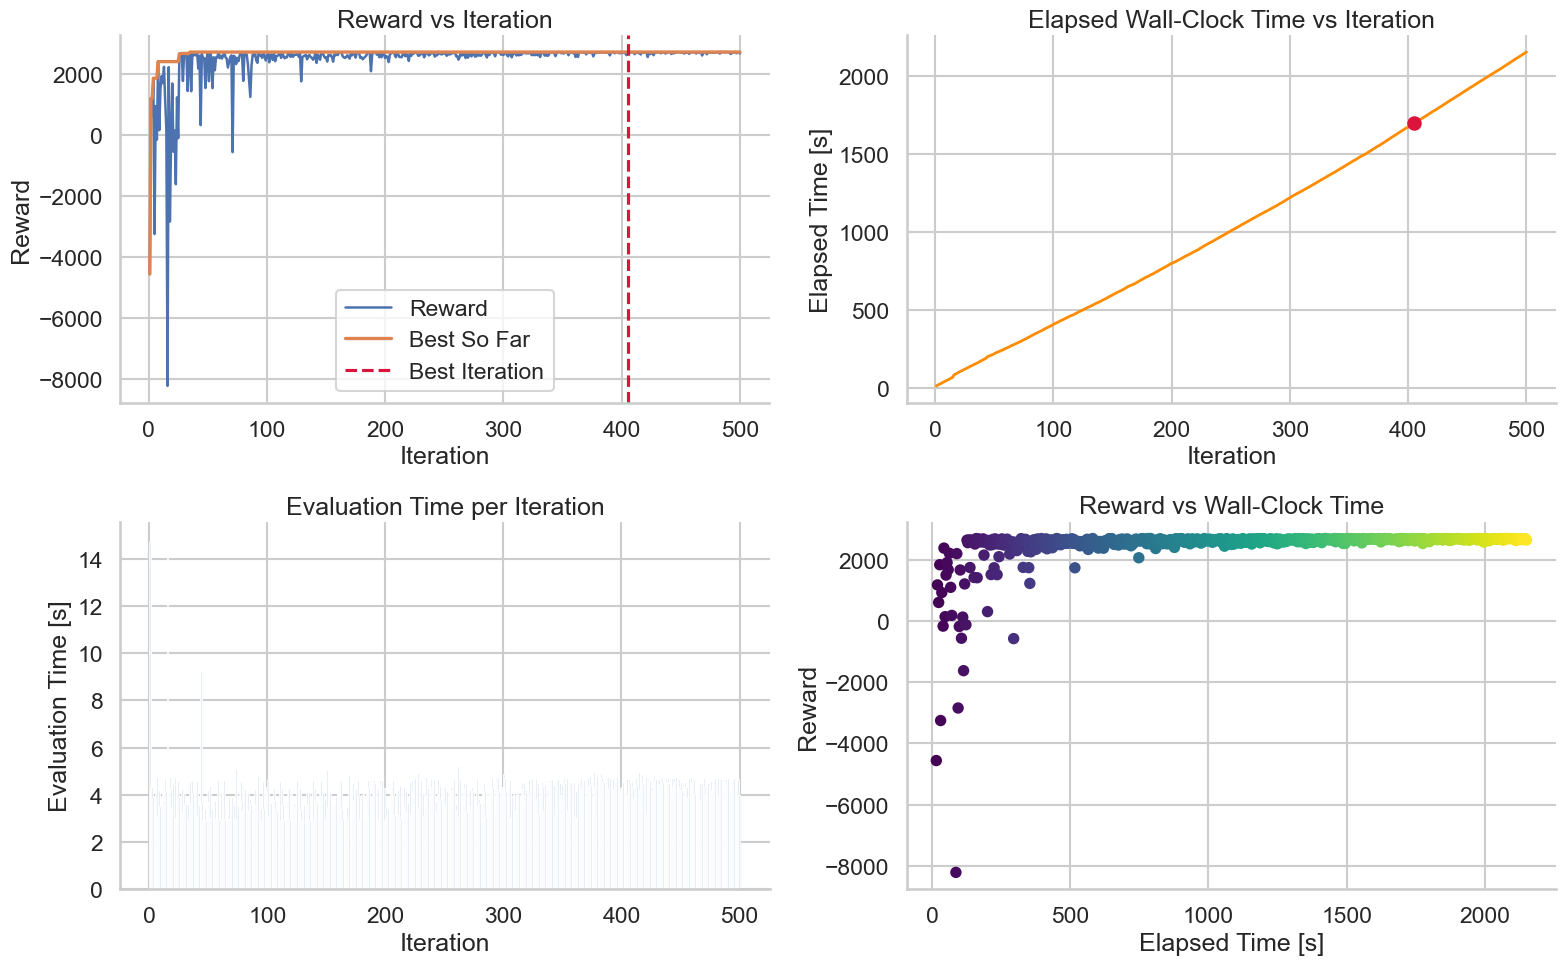

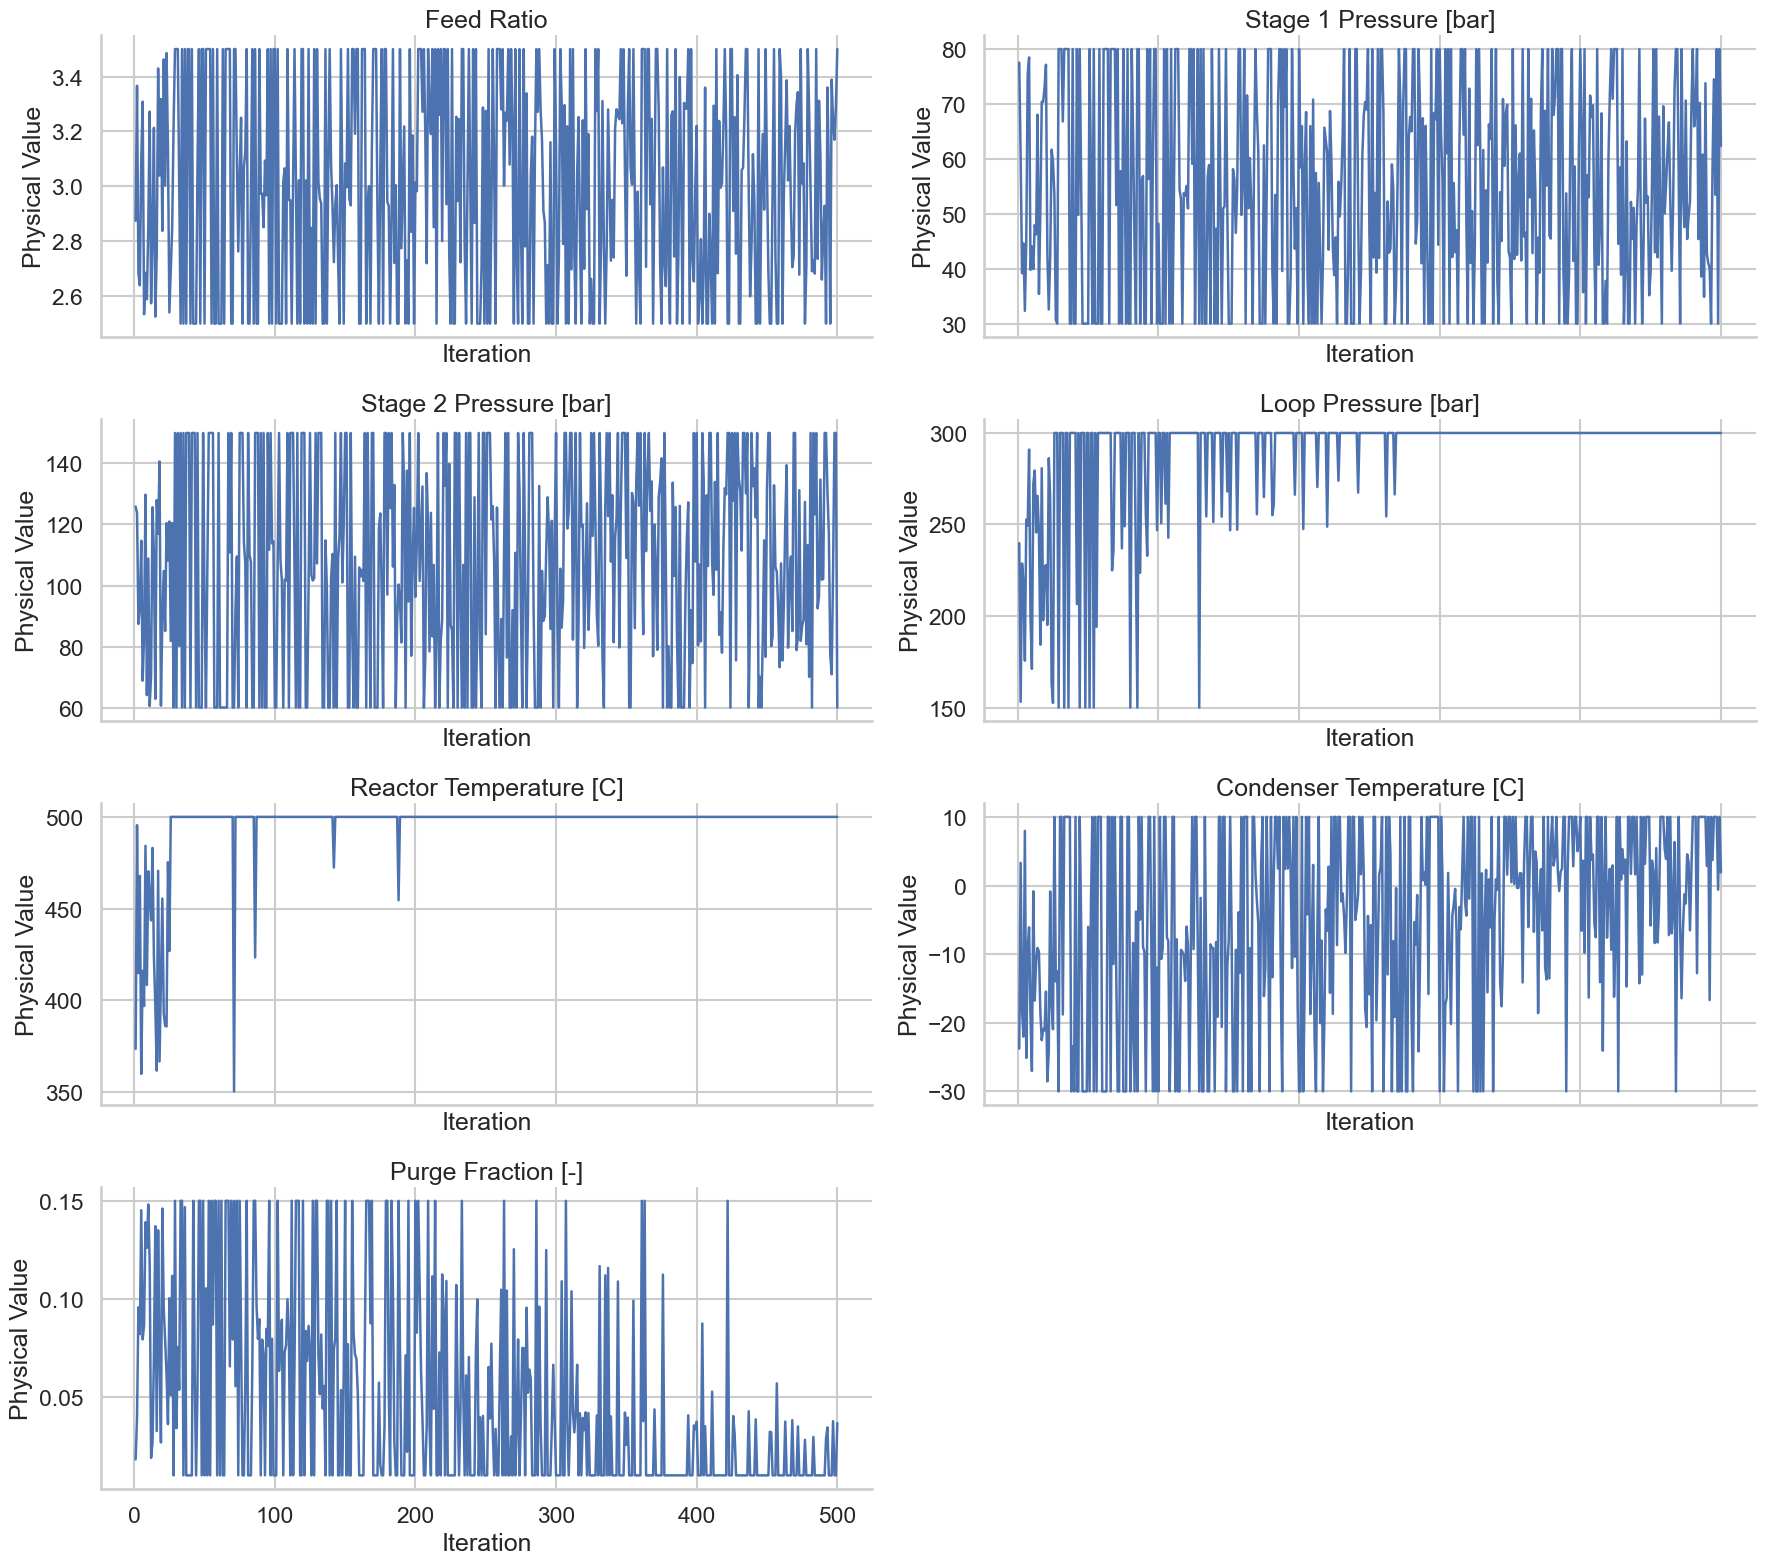

In [10]:
plot_bo_progress(bo_results, bo_summary)
plot_parameter_trajectories(bo_results)

In [3]:
top_k = 10
top_results = bo_results.sort_values('reward', ascending=False).head(top_k).reset_index(drop=True)
display(top_results[[
    'iteration',
    'reward',
    'best_reward_so_far',
    'elapsed_wall_clock_seconds',
    'evaluation_seconds',
    'nh3_kg_per_s',
    'nh3_ton_per_h',
    'power_kw',
] + [f'a{i}' for i in range(1, 8)] + [f'a{i}_physical' for i in range(1, 8)]])

NameError: name 'bo_results' is not defined

## Interpretation Notes

- `Reward vs Iteration` shows whether BO is discovering better operating points or plateauing.
- `Elapsed Wall-Clock Time vs Iteration` shows how long it took to reach the incumbent optimum.
- `Evaluation Time per Iteration` shows whether solve time is stable or drifting.
- The parameter trajectory plot shows whether BO is saturating against bounds or exploring the interior of the feasible space.
- If reward remains negative after 500 evaluations, the next step is usually process-focused rather than algorithm-focused: validate that the chosen manipulated variables and base flowsheet conditions permit NH3 production in the reachable search region.